# Silver Line Phase 1: did commuting patterns change near the stations?
**Question 2.** Commute mode shares and household vehicle availability (ACS B08301, B08201), 2009-2013 vs 2015-2019, Fairfax County, Virginia.

**Same setup as the Q1 and Q3 notebooks:** same 255 Fairfax tracts (ACS values > 0), tract shapes built from the 2014 block file, same treated (Phase 1) and control (five job centres) definitions.

**What this notebook does**
1. Reads commute mode shares (B08301) and household vehicle availability (B08201) for 2009-2013 and 2015-2019.
2. Standardizes 13 features (8 commute modes + 5 vehicle categories) and applies k-means clustering (k chosen by silhouette score, k = 3 to 8).
3. Compares how Phase 1 and control tracts are distributed across clusters in each period.
4. Reports transit and car shares of commuters within 1 mile of the stations.

**Data files** (in `data/` at the repo root):
- `data/ACS/B08301_transport_to_work/` — commute mode (2013 and 2019 ACS 5-year)
- `data/ACS/B08201_household_vehicles/` — household vehicles (2013 and 2019 ACS 5-year)
- `data/ACS/B01003_population/` and `data/ACS/B25001_housing_units/` (for tract selection)
- `data/access_across_america/dc_2014_transit/47900_tr_2014_0700-0859.shp` (tract shapes)
- `data/dc_open_data/dc_metro_stations_regional.geojson` and `dc_metro_lines_regional.geojson`

**How to run:** `Run > Run All Cells` in VS Code.

## 1. Imports and settings

In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from shapely.ops import unary_union
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
warnings.filterwarnings("ignore")

In [ ]:
# --- data file paths (relative to this notebook in analysis/) ---
DATA_DIR = "../data"
OUT_DIR  = "../outputs/q2_commuting_patterns"
os.makedirs(OUT_DIR, exist_ok=True)

F_2014_SHP   = os.path.join(DATA_DIR, "access_across_america", "dc_2014_transit", "47900_tr_2014_0700-0859.shp")
F_STATIONS   = os.path.join(DATA_DIR, "dc_open_data", "dc_metro_stations_regional.geojson")
F_LINES      = os.path.join(DATA_DIR, "dc_open_data", "dc_metro_lines_regional.geojson")
F_ACS_POP    = os.path.join(DATA_DIR, "ACS", "B01003_population")
F_ACS_HU     = os.path.join(DATA_DIR, "ACS", "B25001_housing_units")
F_B08301_13  = os.path.join(DATA_DIR, "ACS", "B08301_transport_to_work", "ACSDT5Y2013.B08301-2026-10-29T061909.csv")
F_B08301_19  = os.path.join(DATA_DIR, "ACS", "B08301_transport_to_work", "ACSDT5Y2019.B08301-2026-10-29T061900.csv")
F_B08201_13  = os.path.join(DATA_DIR, "ACS", "B08201_household_vehicles", "ACSDT5Y2013.B08201-2026-10-29T225514.csv")
F_B08201_19  = os.path.join(DATA_DIR, "ACS", "B08201_household_vehicles", "ACSDT5Y2019.B08201-2026-10-29T225524.csv")

STUDY_FIPS = "51059"

# --- clustering settings ---
K_RANGE = range(3, 9)          # k values to test for silhouette score
N_FEATURES = 13                # 8 commute modes + 5 vehicle categories

# --- map background ---
BACKGROUND = "tiles"
TILE_SOURCES = ["Esri.WorldGrayCanvas", "OpenStreetMap.Mapnik", "USGS.USTopo"]

# --- same design settings as Q1/Q3 ---
TREATED_MILES, CONTROL_RADIUS_MILES, NEAR_METRO_EXCLUDE_MILES = 1.0, 2.0, 1.5
PHASE1 = ["Wiehle-Reston East", "Spring Hill", "Greensboro", "Tysons", "McLean"]
PHASE2 = ["Reston Town Center", "Herndon", "Innovation Center", "Washington Dulles International Airport", "Loudoun Gateway", "Ashburn"]
CONTROL_CENTERS = {"Fair Oaks": (-77.35884, 38.86108), "Chantilly": (-77.44256, 38.88661),
                   "Fair Lakes": (-77.38697, 38.85812), "Braddock": (-77.35531, 38.83597),
                   "George Mason": (-77.31130, 38.83279)}
MI = 1609.344
BLUE, GRAY, PINK = "#08519c", "#7f7f7f", "#e6007e"
COUNTY_FIPS = {"Fairfax County": "51059", "Loudoun County": "51107", "Arlington County": "51013",
               "Prince William County": "51153", "Alexandria city": "51510", "Falls Church city": "51610",
               "Fairfax city": "51600", "Manassas city": "51683", "Manassas Park city": "51685",
               "District of Columbia": "11001"}

## 2. Tract selection (same 255 tracts as Q1/Q3)
ACS population and housing tables are used **only** to reproduce the Q3 tract set (255 Fairfax tracts with population and housing > 0 in both years).

In [3]:
def read_acs(path):
    """Read an ACS file and return {tract_id: value} for Fairfax County tracts."""
    if path.endswith(".xlsx"):
        d = pd.read_excel(path, sheet_name="Data", header=None, dtype=str)
        pairs = [(d.iloc[0, j], d.iloc[2, j]) for j in range(1, d.shape[1])
                 if isinstance(d.iloc[0, j], str) and "estimate" in str(d.iloc[1, j]).lower()]
    else:
        d = pd.read_csv(path, dtype=str)
        d.columns = [c.strip() for c in d.columns]
        pairs = [(c, d.iloc[0][c]) for c in d.columns[1:] if c.endswith("!!Estimate")]
    out = {}
    for name, val in pairs:
        m = re.search(r"Census Tract ([\d.]+), Fairfax County", str(name))
        if m:
            out[f"51059{int(round(float(m.group(1)) * 100)):06d}"] = float(str(val).replace(",", ""))
    return out

pop13 = read_acs(os.path.join(DATA_DIR, "ACS", "B01003_population", "ACSDT5Y2013.B01003-2026-10-29T225439.csv"))
pop19 = read_acs(os.path.join(DATA_DIR, "ACS", "B01003_population", "ACSDT5Y2019.B01003-2026-10-29T225451.csv"))
hu13  = read_acs(os.path.join(DATA_DIR, "ACS", "B25001_housing_units", "ACSDT5Y2013.B25001-2026-11-10T025530.xlsx"))
hu19  = read_acs(os.path.join(DATA_DIR, "ACS", "B25001_housing_units", "ACSDT5Y2019.B25001-2026-11-10T025503.xlsx"))

acs = pd.DataFrame({"pop13": pop13, "pop19": pop19, "hu13": hu13, "hu19": hu19}).dropna()
acs = acs[(acs.pop13 > 0) & (acs.hu13 > 0)]
print(f"ACS tracts with all four values: {len(acs)}   (Q1/Q3 had 255)")

ACS tracts with all four values: 255   (Q1/Q3 had 255)


## 3. Tract shapes, stations and the Silver Line

In [4]:
blocks = gpd.read_file(F_2014_SHP, columns=["geoid"])
blocks = blocks[blocks.geoid.astype(str).str[:5] == STUDY_FIPS].to_crs(32618)
tracts = blocks.assign(t=blocks.geoid.astype(str).str[:11]).dissolve("t")
T = tracts.join(acs, how="inner")
print(f"Tracts joined to geometry: {len(T)}")

stations = gpd.read_file(F_STATIONS).to_crs(32618)
lines = gpd.read_file(F_LINES).to_crs(32618)
silver = lines[lines.NAME.str.lower() == "silver"]
s1 = stations[stations.NAME.isin(PHASE1)].drop_duplicates("NAME").set_index("NAME")
existing = stations[~stations.NAME.isin(PHASE1 + PHASE2)]
buf = lambda g, mi: unary_union(g.geometry.buffer(mi * MI).values)
g1 = buf(s1.reset_index(), TREATED_MILES)
g_existing = buf(existing, TREATED_MILES)
g_any = buf(stations, NEAR_METRO_EXCLUDE_MILES)
s1_union = unary_union(s1.geometry.values)

Tracts joined to geometry: 255


## 4. Commute mode shares (B08301) and vehicle availability (B08201)
For each tract and each period, we compute the **share** of workers using each commute mode (B08301) and the **share** of households with each number of vehicles (B08201). This gives 8 + 5 = 13 features per tract per period.

In [6]:
# B08301: commute mode rows (0-indexed) and their labels
B08301_ROWS = {
    2:  "Drove alone",
    3:  "Carpooled",
    9:  "Public transit",
    16: "Motorcycle",
    17: "Bicycle",
    18: "Walked",
    19: "Other means",
    20: "Worked at home",
}
B08301_TOTAL_ROW = 0  # "Total:"

# B08201: vehicle availability rows (0-indexed) and their labels
B08201_ROWS = {
    1: "No vehicle",
    2: "1 vehicle",
    3: "2 vehicles",
    4: "3 vehicles",
    5: "4+ vehicles",
}
B08201_TOTAL_ROW = 0  # "Total:"

def read_acs_shares(path, row_map, total_row):
    """Read an ACS table and return a DataFrame of shares: index=tract_id, columns=feature names."""
    d = pd.read_csv(path, dtype=str)
    d.columns = [c.strip() for c in d.columns]
    # Build tract_id -> column index mapping for Estimate columns (skip label column 0)
    tract_cols = {}
    for c in d.columns[1:]:
        if c.endswith("!!Estimate"):
            m = re.search(r"Census Tract ([\d.]+), Fairfax County", c)
            if m:
                tid = f"51059{int(round(float(m.group(1)) * 100)):06d}"
                tract_cols[tid] = c
    # Extract values for each row (skip the label column)
    def _val(row_idx, col):
        x = d.iloc[row_idx][col]
        if pd.isna(x):
            return np.nan
        x = str(x).replace(",", "").strip()
        try:
            return float(x)
        except ValueError:
            return np.nan
    records = {}
    for tid, col in tract_cols.items():
        total = _val(total_row, col)
        if pd.isna(total) or total <= 0:
            continue
        row_data = {}
        for row_idx, label in row_map.items():
            val = _val(row_idx, col)
            row_data[label] = val / total if val is not None and not pd.isna(val) else 0.0
        records[tid] = row_data
    return pd.DataFrame.from_dict(records, orient="index")

# Read all four tables
commute13 = read_acs_shares(F_B08301_13, B08301_ROWS, B08301_TOTAL_ROW)
commute19 = read_acs_shares(F_B08301_19, B08301_ROWS, B08301_TOTAL_ROW)
vehicle13 = read_acs_shares(F_B08201_13, B08201_ROWS, B08201_TOTAL_ROW)
vehicle19 = read_acs_shares(F_B08201_19, B08201_ROWS, B08201_TOTAL_ROW)

print(f"B08301 2013: {commute13.shape[0]} tracts, {commute13.shape[1]} modes")
print(f"B08301 2019: {commute19.shape[0]} tracts, {commute19.shape[1]} modes")
print(f"B08201 2013: {vehicle13.shape[0]} tracts, {vehicle13.shape[1]} categories")
print(f"B08201 2019: {vehicle19.shape[0]} tracts, {vehicle19.shape[1]} categories")

B08301 2013: 255 tracts, 8 modes
B08301 2019: 255 tracts, 8 modes
B08201 2013: 255 tracts, 5 categories
B08201 2019: 256 tracts, 5 categories


## 5. Build the feature matrix and standardize
Combine commute mode shares and vehicle availability shares into a single 13-column matrix for each period. Standardize (z-score) so that no single feature dominates the distance calculation.

In [7]:
# Combine commute + vehicle features for each period
feat13 = pd.concat([commute13, vehicle13], axis=1)
feat19 = pd.concat([commute19, vehicle19], axis=1)

# Keep only tracts that appear in both periods and in our study set
common = feat13.index.intersection(feat19.index).intersection(T.index)
feat13 = feat13.loc[common]
feat19 = feat19.loc[common]
print(f"Tracts with complete data in both periods: {len(common)}")
print(f"Features: {list(feat13.columns)}")

# Standardize (fit on period 1, transform both periods for comparability)
scaler = StandardScaler()
X13 = scaler.fit_transform(feat13)
X19 = scaler.transform(feat19)  # use period 1 mean/std for both

print(f"\nStandardized feature matrix: {X13.shape}")
print(f"Mean (should be ~0): {X13.mean(axis=0).round(3)}")
print(f"Std (should be ~1): {X13.std(axis=0).round(3)}")

Tracts with complete data in both periods: 255
Features: ['Drove alone', 'Carpooled', 'Public transit', 'Motorcycle', 'Bicycle', 'Walked', 'Other means', 'Worked at home', 'No vehicle', '1 vehicle', '2 vehicles', '3 vehicles', '4+ vehicles']

Standardized feature matrix: (255, 13)
Mean (should be ~0): [ 0.  0.  0. -0. -0.  0. -0.  0.  0. -0.  0.  0.  0.]
Std (should be ~1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 6. K-means clustering (k chosen by silhouette score)
We test k = 3 to 8 on the period 1 (2009-2013) standardized features and pick the k with the highest mean silhouette score. The chosen k-means model is then used to assign **both** periods to the same cluster definitions, so we can compare distributions and track movement between clusters.

In [8]:
# Silhouette score for each k
sil_scores = {}
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = km.fit_predict(X13)
    sil_scores[k] = silhouette_score(X13, labels)

sil_df = pd.DataFrame({"k": list(sil_scores.keys()), "silhouette": list(sil_scores.values())})
best_k = sil_df.loc[sil_df.silhouette.idxmax(), "k"]
print("Silhouette scores by k:")
print(sil_df.to_string(index=False))
print(f"\nBest k = {best_k} (silhouette = {sil_df.silhouette.max():.3f})")

# Fit final model on period 1 with best k
km_final = KMeans(n_clusters=best_k, n_init=20, random_state=42)
cluster13 = km_final.fit_predict(X13)
cluster19 = km_final.predict(X19)  # assign period 2 to the same centroids

# Store assignments
T["cluster_2013"] = pd.Series(cluster13, index=feat13.index)
T["cluster_2019"] = pd.Series(cluster19, index=feat19.index)
print(f"\nCluster assignments (k={best_k}):")
print(f"  2013: {pd.Series(cluster13).value_counts().sort_index().to_dict()}")
print(f"  2019: {pd.Series(cluster19).value_counts().sort_index().to_dict()}")

Silhouette scores by k:
 k  silhouette
 3    0.138159
 4    0.140759
 5    0.151109
 6    0.143457
 7    0.157276
 8    0.129498

Best k = 7 (silhouette = 0.157)

Cluster assignments (k=7):
  2013: {0: 98, 1: 21, 2: 72, 3: 21, 4: 17, 5: 18, 6: 8}
  2019: {0: 85, 1: 26, 2: 91, 3: 9, 4: 19, 5: 21, 6: 4}


## 7. Treated and control groups (same rules as Q1/Q3)

In [9]:
T["group"] = "other"
T.loc[T.intersects(g1) & ~T.intersects(g_existing), "group"] = "Phase 1"
circles = {k: gpd.GeoSeries(gpd.points_from_xy([x], [y]), crs=4326).to_crs(32618).iloc[0].buffer(CONTROL_RADIUS_MILES * MI)
           for k, (x, y) in CONTROL_CENTERS.items()}
ctl_ids, place_tracts = set(), {}
for k, c in circles.items():
    ids = T[T.intersects(c) & ~T.intersects(g_any) & (T.group != "Phase 1")].index
    place_tracts[k] = ids; ctl_ids |= set(ids)
T.loc[T.index.isin(ctl_ids), "group"] = "Control"

n_t, n_c = (T.group == "Phase 1").sum(), (T.group == "Control").sum()
print(f"Treated: {n_t}, Control: {n_c}   (Q1/Q3: 21 and 36)")
P = T[T.group == "Phase 1"].copy(); P["treat"] = 1
K = T[T.group == "Control"].copy(); K["treat"] = 0

Treated: 21, Control: 36   (Q1/Q3: 21 and 36)


## 8. Table 1: cluster profiles
Mean commute mode share and vehicle availability share for each cluster (pooled across both periods), plus the number of tracts in each cluster.

In [10]:
# Pool both periods for cluster profiles
feat_all = pd.concat([feat13, feat19], keys=["2013", "2019"])
cluster_all = np.concatenate([cluster13, cluster19])
feat_all["cluster"] = cluster_all

rows = []
for c in range(best_k):
    sub = feat_all[feat_all.cluster == c]
    row = {"Cluster": c, "Tracts (pooled)": len(sub) // 2}
    for col in feat13.columns:
        row[col] = sub[col].mean()
    rows.append(row)
tab1 = pd.DataFrame(rows).set_index("Cluster")

print("TABLE 1: Cluster profiles (mean share, pooled 2013+2019)")
display(tab1.round(3))

TABLE 1: Cluster profiles (mean share, pooled 2013+2019)


,Tracts (pooled),Drove alone,Carpooled,Public transit,Motorcycle,Bicycle,Walked,Other means,Worked at home,No vehicle,1 vehicle,2 vehicles,3 vehicles,4+ vehicles
Cluster,,,,,,,,,,,,,,
0,91,0.746,0.102,0.080,0.001,0.001,0.013,0.006,0.048,0.032,0.309,0.453,0.144,0.062
1,23,0.616,0.155,0.127,0.001,0.002,0.029,0.026,0.039,0.115,0.390,0.336,0.111,0.048
2,81,0.746,0.082,0.063,0.001,0.002,0.009,0.008,0.087,0.015,0.133,0.487,0.246,0.118
3,15,0.696,0.072,0.086,0.002,0.002,0.085,0.007,0.045,0.067,0.381,0.409,0.107,0.036
4,18,0.610,0.072,0.248,0.001,0.002,0.013,0.006,0.045,0.060,0.499,0.344,0.071,0.026
5,19,0.695,0.085,0.103,0.003,0.019,0.018,0.006,0.070,0.032,0.284,0.458,0.158,0.069
6,6,0.724,0.079,0.081,0.021,0.005,0.009,0.003,0.073,0.048,0.381,0.407,0.118,0.046


## 9. Table 2: distribution of Phase 1 and control tracts across clusters
How many Phase 1 (treated) and control tracts fall in each cluster, in each period. This shows whether station-area tracts concentrate in particular commute-pattern groups and whether that changes over time.

In [11]:
rows = []
for period, col in (("2013", "cluster_2013"), ("2019", "cluster_2019")):
    for c in range(best_k):
        n_p1 = int((P[col] == c).sum())
        n_ctl = int((K[col] == c).sum())
        n_all = int((T[col] == c).sum())
        rows.append({"Period": period, "Cluster": c,
                     "Phase 1 tracts": n_p1, "Phase 1 share": n_p1 / len(P) if len(P) else 0,
                     "Control tracts": n_ctl, "Control share": n_ctl / len(K) if len(K) else 0,
                     "All tracts": n_all})
tab2 = pd.DataFrame(rows)

print("TABLE 2: Distribution of Phase 1 and control tracts across clusters")
display(tab2)

TABLE 2: Distribution of Phase 1 and control tracts across clusters


,Period,Cluster,Phase 1 tracts,Phase 1 share,Control tracts,Control share,All tracts
0,2013,0,4,0.190476,17,0.472222,98
1,2013,1,2,0.095238,0,0.000000,21
2,2013,2,6,0.285714,16,0.444444,72
3,2013,3,6,0.285714,2,0.055556,21
4,2013,4,0,0.000000,0,0.000000,17
5,2013,5,1,0.047619,1,0.027778,18
6,2013,6,2,0.095238,0,0.000000,8
7,2019,0,4,0.190476,12,0.333333,85
8,2019,1,0,0.000000,0,0.000000,26
9,2019,2,8,0.380952,20,0.555556,91


## 10. Table 3: transit and car shares within 1 mile of Phase 1 stations
Aggregate commute mode shares for all tracts within 1 mile of a Phase 1 station (the treated group), comparing 2013 vs 2019. Focus on transit and car (drove alone + carpool) shares.

In [12]:
# Weighted average of commute shares for Phase 1 tracts (weighted by total workers)
# We don't have total workers per tract directly, so use unweighted mean of tract shares
p1_13 = commute13.loc[P.index.intersection(commute13.index)]
p1_19 = commute19.loc[P.index.intersection(commute19.index)]

rows = []
for mode in ["Drove alone", "Carpooled", "Public transit", "Worked at home"]:
    rows.append({"Commute mode": mode,
                 "2013 (Phase 1 tracts)": p1_13[mode].mean(),
                 "2019 (Phase 1 tracts)": p1_19[mode].mean(),
                 "Change (pp)": 100 * (p1_19[mode].mean() - p1_13[mode].mean())})

# Also compute car total and transit total
car13 = p1_13[["Drove alone", "Carpooled"]].mean().sum()
car19 = p1_19[["Drove alone", "Carpooled"]].mean().sum()
transit13 = p1_13["Public transit"].mean()
transit19 = p1_19["Public transit"].mean()
rows.append({"Commute mode": "Car (alone + carpool)", "2013 (Phase 1 tracts)": car13, "2019 (Phase 1 tracts)": car19,
             "Change (pp)": 100 * (car19 - car13)})
rows.append({"Commute mode": "Transit", "2013 (Phase 1 tracts)": transit13, "2019 (Phase 1 tracts)": transit19,
             "Change (pp)": 100 * (transit19 - transit13)})

tab3 = pd.DataFrame(rows)
print("TABLE 3: Commute mode shares in Phase 1 station tracts (mean of tract shares)")
display(tab3.round(3))
print(f"\nTransit share: {transit13:.1%} -> {transit19:.1%}  (change: {100*(transit19-transit13):+.1f} pp)")
print(f"Car share:     {car13:.1%} -> {car19:.1%}  (change: {100*(car19-car13):+.1f} pp)")

TABLE 3: Commute mode shares in Phase 1 station tracts (mean of tract shares)


,Commute mode,2013 (Phase 1 tracts),2019 (Phase 1 tracts),Change (pp)
0,Drove alone,0.750,0.708,-4.159
1,Carpooled,0.068,0.060,-0.812
2,Public transit,0.070,0.090,1.980
3,Worked at home,0.070,0.096,2.578
4,Car (alone + carpool),0.818,0.768,-4.970
5,Transit,0.070,0.090,1.980



Transit share: 7.0% -> 9.0%  (change: +2.0 pp)
Car share:     81.8% -> 76.8%  (change: -5.0 pp)


## 11. Map helpers (open-source background)

In [13]:
Tm = T.to_crs(3857)
P_m, K_m = Tm.loc[P.index], Tm.loc[K.index]
s1_m, st_m, silver_m = s1.to_crs(3857), stations.to_crs(3857), silver.to_crs(3857)
county_m = gpd.GeoSeries([Tm.geometry.union_all() if hasattr(Tm.geometry, "union_all") else Tm.unary_union], crs=3857)
to_m = lambda g: gpd.GeoSeries([g], crs=32618).to_crs(3857).iloc[0]
rings_m = {r: to_m(buf(s1.reset_index(), r)) for r in (0.5, 1.0)}
circles_m = {k: to_m(c) for k, c in circles.items()}
centres_m = {k: to_m(gpd.GeoSeries(gpd.points_from_xy([v[0]], [v[1]]), crs=4326).to_crs(32618).iloc[0]) for k, v in CONTROL_CENTERS.items()}
TILES_OK = {"state": BACKGROUND == "tiles", "credit": ""}

def _provider(name):
    import contextily as cx
    src = cx.providers
    for part in name.split("."):
        src = src[part]
    return src

def add_background(ax, xlim, ylim):
    """Open-source background: keyless tiles if reachable, otherwise tract and county outlines."""
    ax.set_xlim(xlim); ax.set_ylim(ylim); ax.set_aspect("equal")
    if TILES_OK["state"]:
        try:
            import contextily as cx
        except ImportError:
            cx = None; TILES_OK["state"] = False
        for name in (TILE_SOURCES if cx else []):
            try:
                src = _provider(name)
                if hasattr(src, "requires_token") and src.requires_token():
                    print(f"Skipping {name}: needs an API key"); continue
                cx.add_basemap(ax, crs="EPSG:3857", source=src, attribution=False, zoom="auto")
                ax.set_xlim(xlim); ax.set_ylim(ylim)
                TILES_OK["credit"] = "Basemap: " + re.sub(r"<[^>]+>|&copy;", "", str(src.get("attribution", name))).replace("  ", " ").strip()
                return
            except Exception as e:
                print(f"Tiles from {name} unavailable ({type(e).__name__}); trying the next source.")
        TILES_OK["state"] = False
        print("No keyless tiles could be downloaded -> using tract and county outlines instead.")
    ax.set_facecolor("#f3f3f1")
    Tm.boundary.plot(ax=ax, color="#bdbdbd", lw=.4, zorder=1)
    gpd.GeoSeries(county_m.boundary).plot(ax=ax, color="#7a7a7a", lw=1.0, zorder=1)

def credit(fig, extra=""):
    txt = (TILES_OK["credit"] if TILES_OK["state"] else "Background: census tract outlines (2010) from the Access Across America block file") + extra
    fig.text(0.5, 0.005, txt, ha="center", va="bottom", fontsize=8, color="#555555")

def pad_bounds(b, f=0.06, ratio=None):
    w, h = b[2] - b[0], b[3] - b[1]; xl, xr, yb, yt = b[0] - w * f, b[2] + w * f, b[1] - h * f, b[3] + h * f
    if ratio:
        cx_, cy_, W = (xl + xr) / 2, (yb + yt) / 2, xr - xl
        H = W / ratio
        if (yt - yb) > H:
            H = yt - yb; W = H * ratio
        xl, xr, yb, yt = cx_ - W / 2, cx_ + W / 2, cy_ - H / 2, cy_ + H / 2
    return (xl, xr), (yb, yt)

def halo(): return [pe.withStroke(linewidth=3, foreground="white")]

def draw_stations(ax, labels=True, offsets=None):
    silver_m.plot(ax=ax, color=PINK, lw=3.2, zorder=6)
    for r, ls in ((0.5, "-"), (1.0, "--")):
        gpd.GeoSeries([rings_m[r]], crs=3857).boundary.plot(ax=ax, color="k", lw=1.3, ls=ls, zorder=7)
    s1_m.plot(ax=ax, color="white", edgecolor=PINK, linewidth=2.4, markersize=55, zorder=8)
    if labels:
        offsets = offsets or {}
        for n, r in s1_m.iterrows():
            ax.annotate(n, (r.geometry.x, r.geometry.y), xytext=offsets.get(n, (0, 12)), textcoords="offset points", ha="center",
                        fontsize=9, fontweight="bold", zorder=10, path_effects=halo())

## 12. Figure 1: study area

In [14]:
fig, ax = plt.subplots(figsize=(13, 8.5))
xl, yl = pad_bounds(unary_union([P_m.geometry.union_all() if hasattr(P_m.geometry, "union_all") else P_m.unary_union, *circles_m.values()]).bounds, 0.05, 1.5)
add_background(ax, xl, yl)
Tm.boundary.plot(ax=ax, color="#9a9a9a", lw=.35, zorder=2)
K_m.plot(ax=ax, color="#6b7a99", alpha=.40, edgecolor="#4a5875", linewidth=.6, zorder=3)
P_m.plot(ax=ax, color=PINK, alpha=.32, edgecolor=PINK, linewidth=.9, zorder=3)
for k, c in circles_m.items():
    gpd.GeoSeries([c], crs=3857).boundary.plot(ax=ax, color="#222", lw=1.4, ls="--", zorder=7)
    ax.plot(centres_m[k].x, centres_m[k].y, "k*", ms=11, zorder=9)
    ax.annotate(k, (centres_m[k].x, centres_m[k].y), xytext=(0, 12), textcoords="offset points", ha="center", fontsize=9, fontweight="bold", zorder=10, path_effects=halo())
draw_stations(ax, offsets={"Wiehle-Reston East": (0, -20), "Spring Hill": (-48, 14), "Greensboro": (-55, -8), "Tysons": (0, -26), "McLean": (28, 16)})
ax.set_xlim(xl); ax.set_ylim(yl); ax.axis("off")
ax.legend(handles=[Patch(fc=PINK, alpha=.4, ec=PINK, label=f"Phase 1 station tracts (n={len(P)})"),
                   Patch(fc="#6b7a99", alpha=.5, ec="#4a5875", label=f"Control place tracts (n={len(K)})"),
                   Line2D([], [], color=PINK, lw=3, label="Silver Line"),
                   Line2D([], [], marker="o", mfc="w", mec=PINK, mew=2.2, ls="", label="Phase 1 stations (opened Jul 2014)"),
                   Line2D([], [], color="k", lw=1.3, label="0.5 mile / 1 mile (dashed) from Phase 1 stations"),
                   Line2D([], [], color="#222", lw=1.4, ls="--", marker="*", mfc="k", label="2-mile circle around control place centre")],
          loc="lower left", fontsize=9, frameon=True, framealpha=.92)
ax.set_title("Study area: Phase 1 station tracts and no-Metro control places, Fairfax County", fontsize=13, fontweight="bold", loc="left")
credit(fig); fig.tight_layout(rect=(0, 0.02, 1, 1)); fig.savefig(os.path.join(OUT_DIR, "fig1_study_area_map.png"), dpi=140, bbox_inches="tight"); plt.close(fig)

Tiles from Esri.WorldGrayCanvas unavailable (SSLError); trying the next source.
Tiles from OpenStreetMap.Mapnik unavailable (SSLError); trying the next source.
Tiles from USGS.USTopo unavailable (SSLError); trying the next source.
No keyless tiles could be downloaded -> using tract and county outlines instead.


## 13. Figure 2: cluster assignment map (2013 and 2019)
Each tract is colored by its k-means cluster assignment. Phase 1 tracts are outlined in pink, control tracts in blue-gray.

In [15]:
cmap = plt.get_cmap("tab10")
cluster_colors = [cmap(i) for i in range(best_k)]

xl, yl = pad_bounds(Tm.total_bounds, 0.04, 1.55)
fig, axs = plt.subplots(1, 2, figsize=(21, 8.4))
for ax, (period, col) in zip(axs, [("2013 (2009-2013 ACS)", "cluster_2013"), ("2019 (2015-2019 ACS)", "cluster_2019")]):
    add_background(ax, xl, yl)
    for c in range(best_k):
        q = Tm[T[col] == c]
        if len(q): q.plot(ax=ax, color=cluster_colors[c], alpha=.75, edgecolor="#444", linewidth=.6, zorder=3)
    # Outline Phase 1 and control tracts
    P_m.boundary.plot(ax=ax, color=PINK, linewidth=1.8, zorder=5)
    K_m.boundary.plot(ax=ax, color="#2c3e6b", linewidth=1.4, zorder=5)
    draw_stations(ax, offsets={"Wiehle-Reston East": (0, -22), "Spring Hill": (-55, 14), "Greensboro": (-62, -6), "Tysons": (4, -26), "McLean": (30, 16)})
    ax.set_xlim(xl); ax.set_ylim(yl); ax.axis("off")
    ax.set_title(f"Cluster assignment, {period}", fontsize=13, fontweight="bold")
    ax.legend(handles=[Patch(fc=cluster_colors[c], ec="#444", label=f"Cluster {c}") for c in range(best_k)] +
              [Line2D([], [], color=PINK, lw=2, label="Phase 1 tracts"),
               Line2D([], [], color="#2c3e6b", lw=1.5, label="Control tracts")],
              loc="upper center", bbox_to_anchor=(.5, -.02), ncol=4, frameon=False, fontsize=9)
fig.suptitle(f"K-means clusters of commute patterns (k={best_k}, chosen by silhouette score)", fontsize=15, fontweight="bold", y=.995)
credit(fig); fig.tight_layout(rect=(0, 0.02, 1, 0.98)); fig.savefig(os.path.join(OUT_DIR, "fig2_cluster_map.png"), dpi=130, bbox_inches="tight"); plt.close(fig)

## 14. Figure 3: cluster profiles and distribution
Left: bar chart of mean commute mode shares by cluster. Right: stacked bar chart showing the distribution of Phase 1 and control tracts across clusters in each period.

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw=dict(width_ratios=[1.2, 1]))

# Left: cluster profiles (top 5 commute modes)
a = axs[0]
top_modes = ["Drove alone", "Carpooled", "Public transit", "Worked at home", "Walked"]
x = np.arange(best_k)
width = 0.15
for i, mode in enumerate(top_modes):
    vals = [tab1.loc[c, mode] for c in range(best_k)]
    a.bar(x + i * width, vals, width, label=mode)
a.set_xticks(x + width * 2)
a.set_xticklabels([f"Cluster {c}" for c in range(best_k)])
a.set_ylabel("Mean share of workers")
a.set_title("Cluster profiles: commute mode shares", loc="left", fontweight="bold")
a.spines[["top", "right"]].set_visible(False); a.grid(axis="y", alpha=.25); a.legend(fontsize=9, loc="upper right")

# Right: distribution of Phase 1 and control tracts across clusters
a = axs[1]
x = np.arange(best_k)
width = 0.35
for i, (period, col) in enumerate([("2013", "cluster_2013"), ("2019", "cluster_2019")]):
    p1_counts = [int((P[col] == c).sum()) for c in range(best_k)]
    ctl_counts = [int((K[col] == c).sum()) for c in range(best_k)]
    a.bar(x - width/2 + i*0.05, p1_counts, width*0.9, label=f"Phase 1 ({period})", color=PINK, alpha=.7 if i==0 else 1)
    a.bar(x + width/2 - i*0.05, ctl_counts, width*0.9, label=f"Control ({period})", color="#6b7a99", alpha=.7 if i==0 else 1)
a.set_xticks(x)
a.set_xticklabels([f"Cluster {c}" for c in range(best_k)])
a.set_ylabel("Number of tracts")
a.set_title("Phase 1 vs control tracts by cluster", loc="left", fontweight="bold")
a.spines[["top", "right"]].set_visible(False); a.grid(axis="y", alpha=.25); a.legend(fontsize=9)

fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "fig3_cluster_profiles.png"), dpi=130, bbox_inches="tight"); plt.close(fig)

## 15. View the results

fig1_study_area_map.png


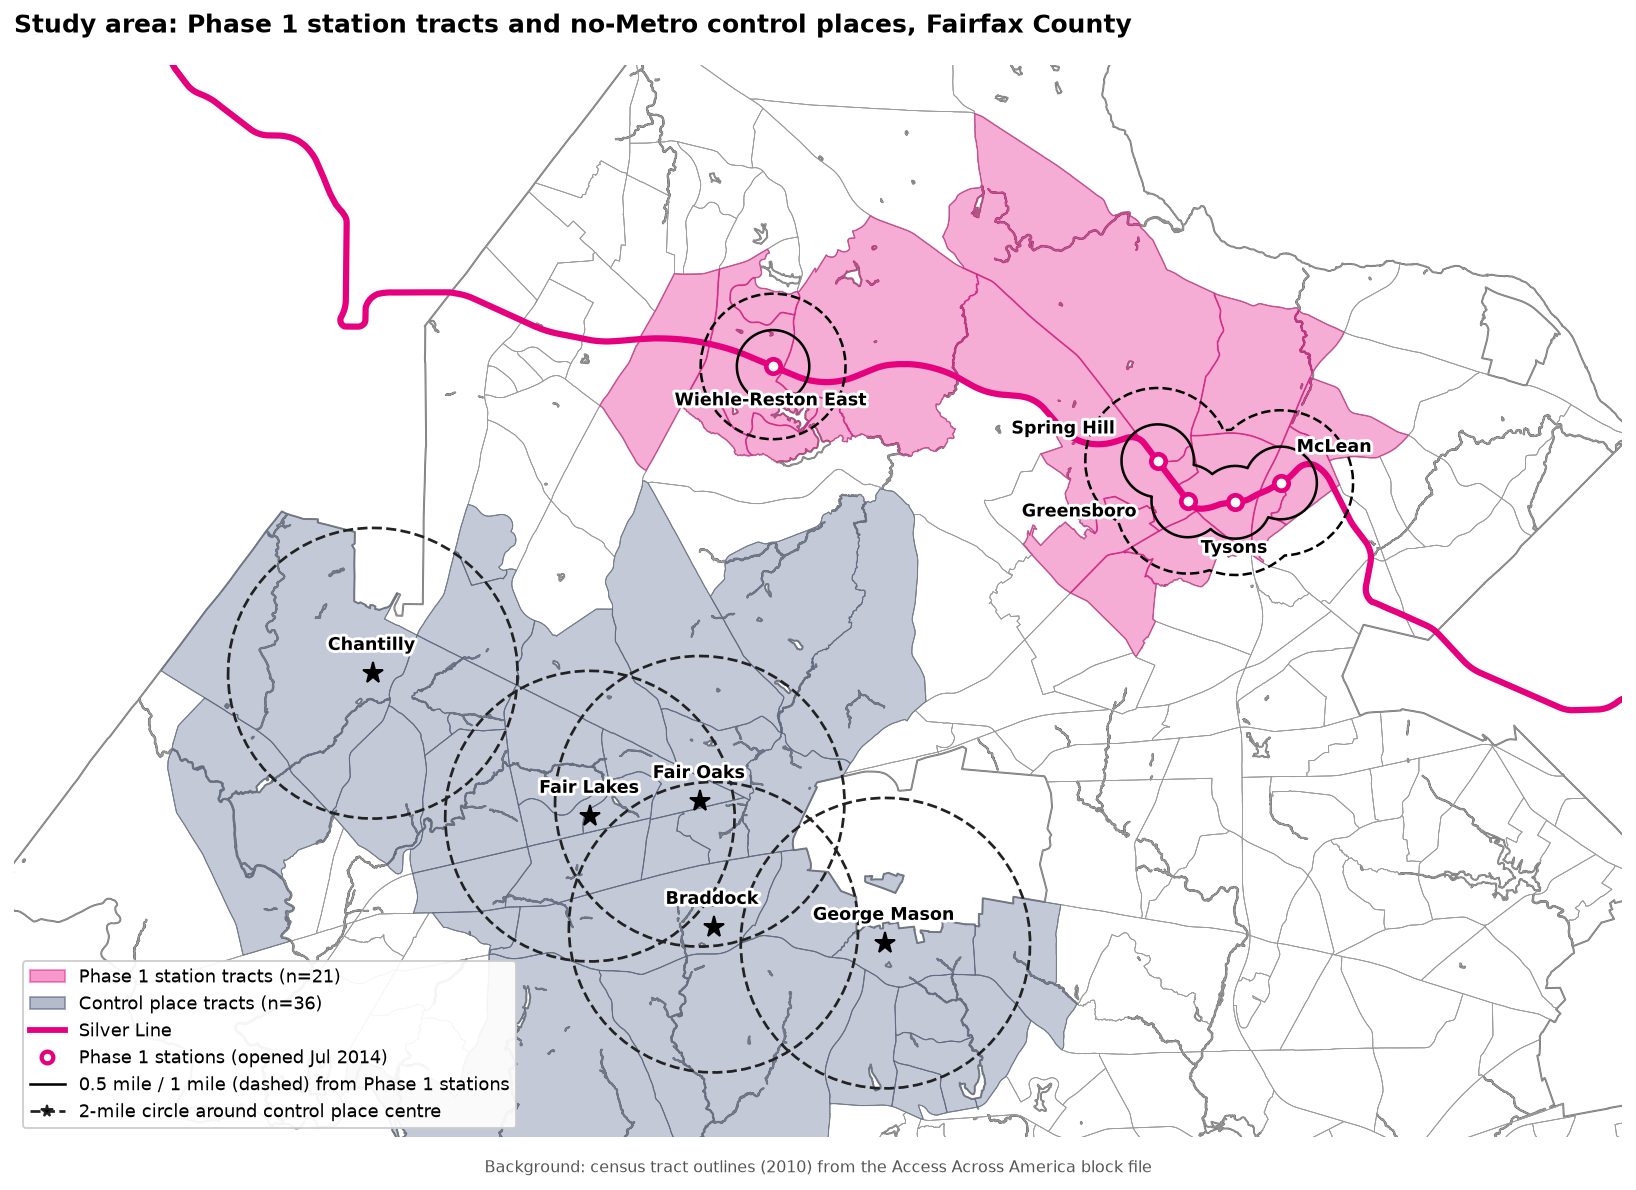

fig2_cluster_map.png


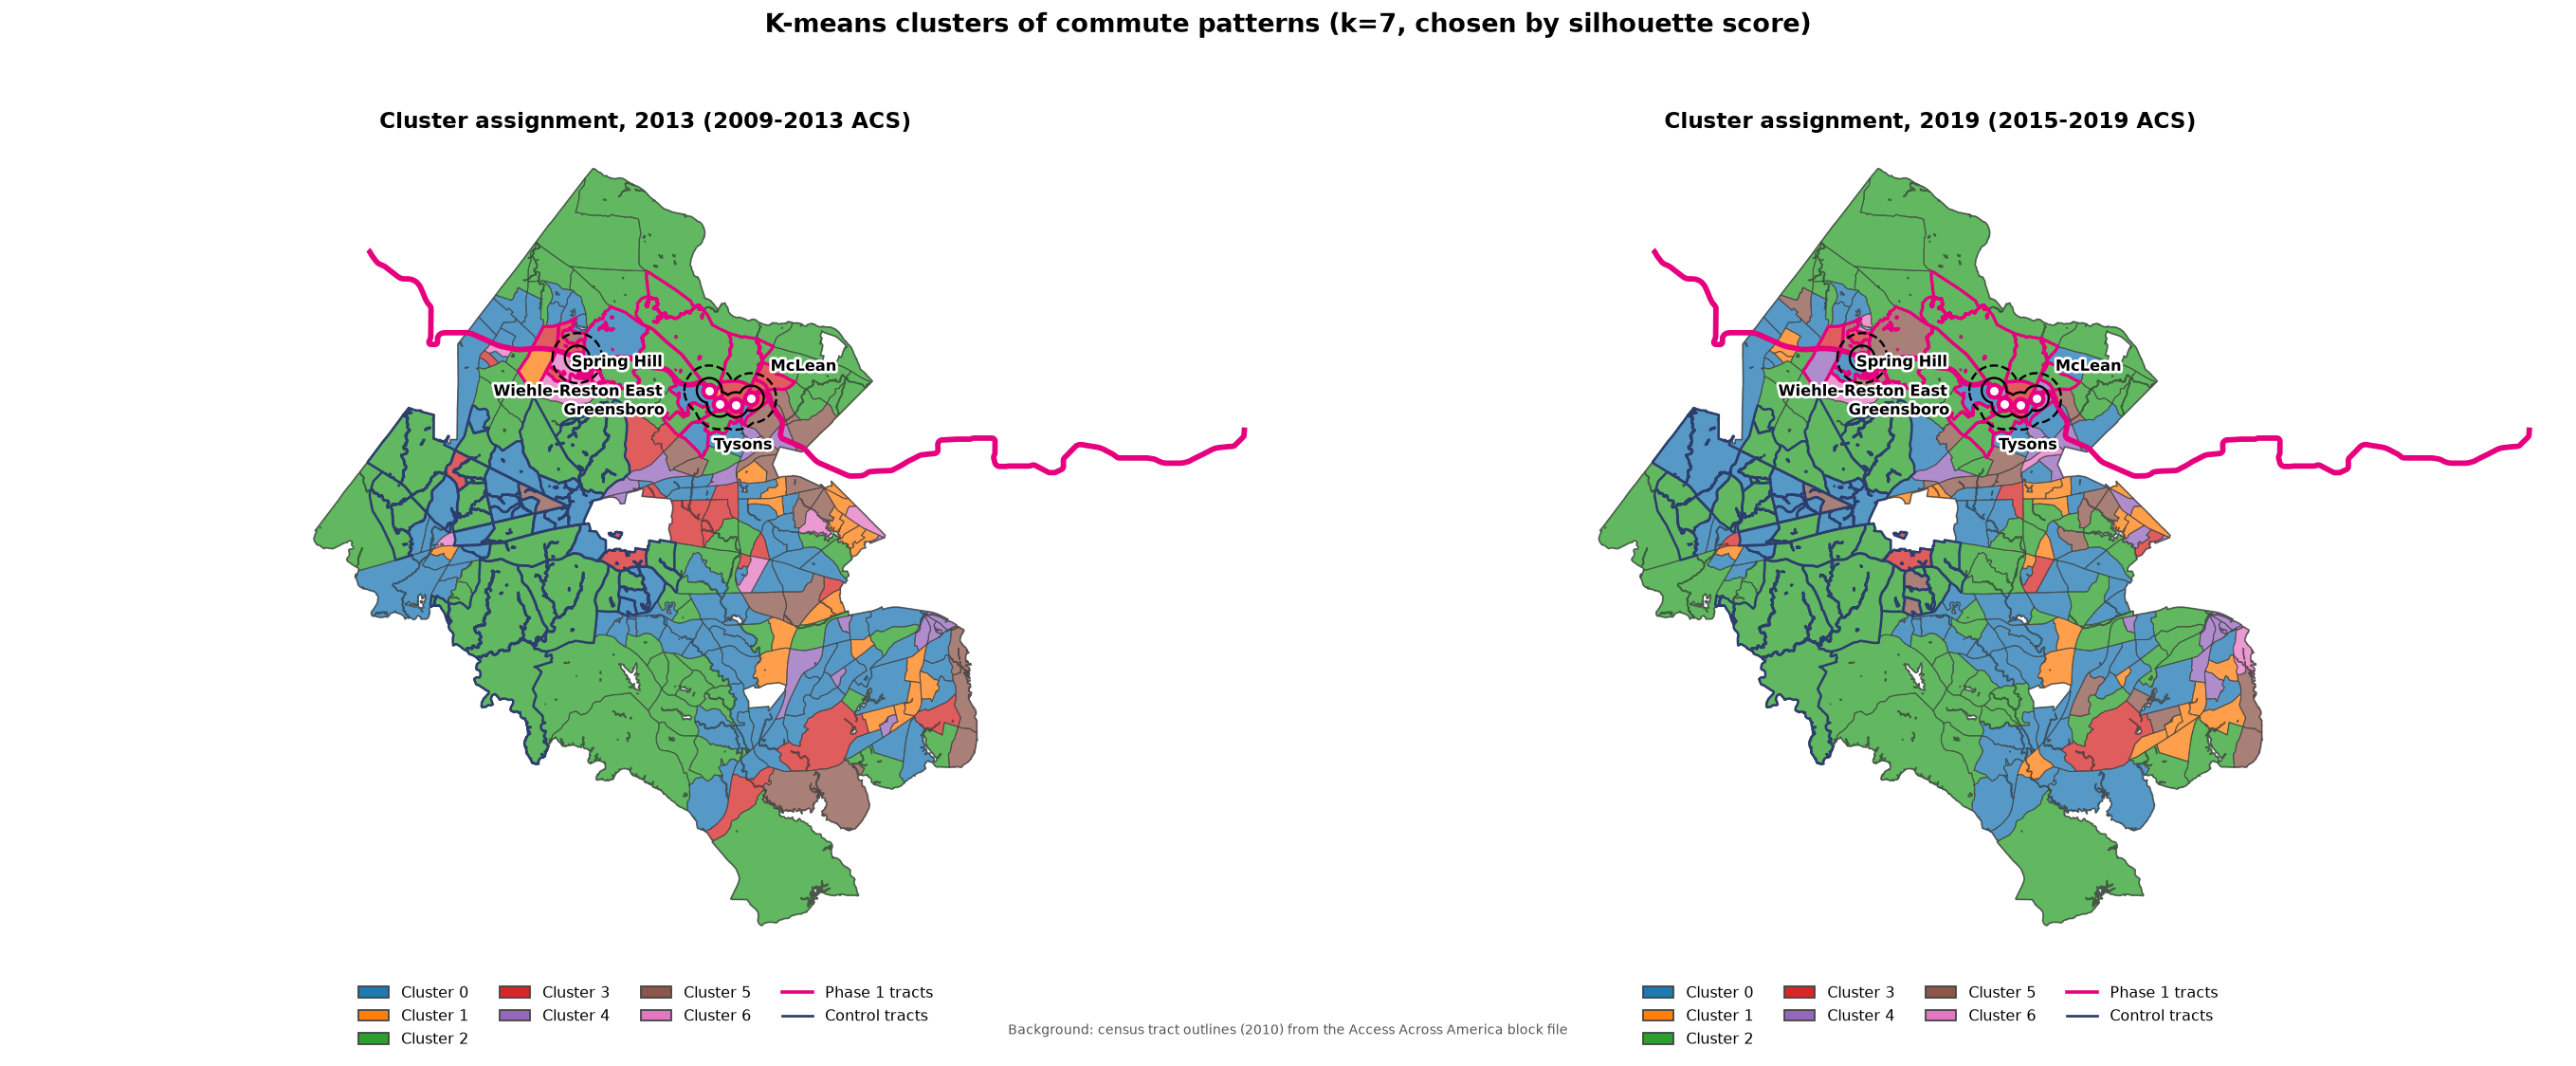

fig3_cluster_profiles.png


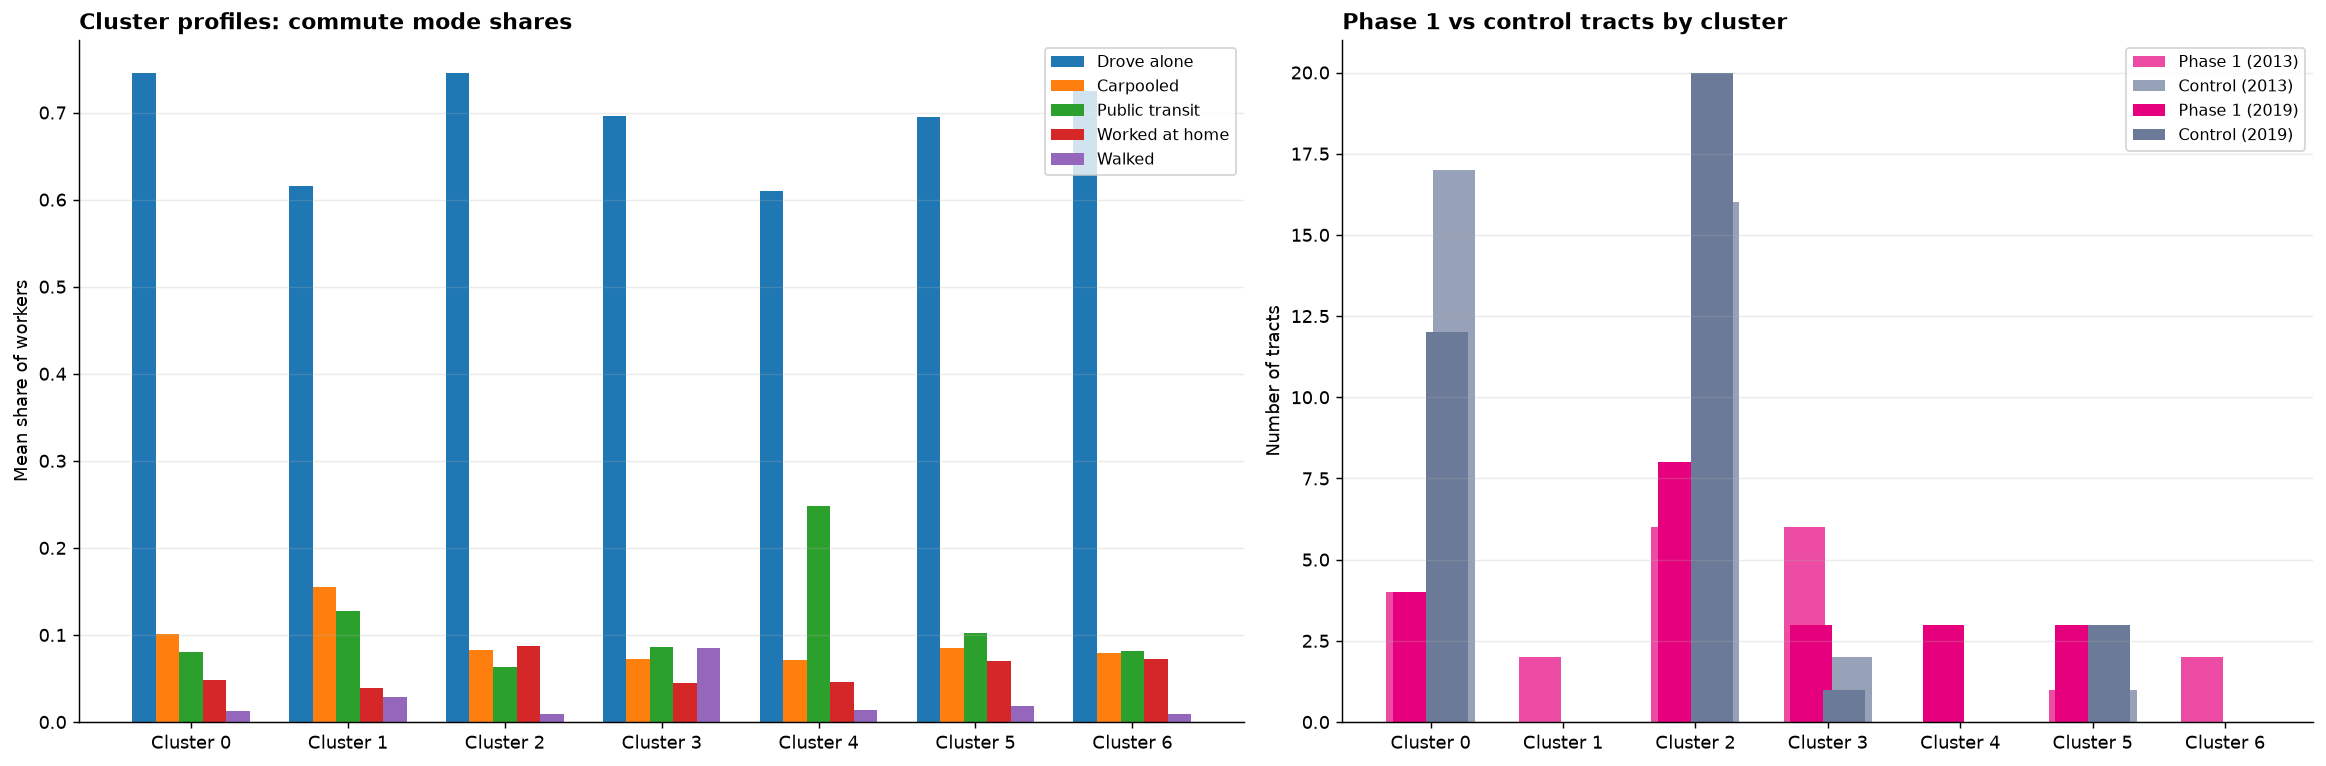

TABLE 1: cluster profiles


,Tracts (pooled),Drove alone,Carpooled,Public transit,Motorcycle,Bicycle,Walked,Other means,Worked at home,No vehicle,1 vehicle,2 vehicles,3 vehicles,4+ vehicles
Cluster,,,,,,,,,,,,,,
0,91,0.746,0.102,0.080,0.001,0.001,0.013,0.006,0.048,0.032,0.309,0.453,0.144,0.062
1,23,0.616,0.155,0.127,0.001,0.002,0.029,0.026,0.039,0.115,0.390,0.336,0.111,0.048
2,81,0.746,0.082,0.063,0.001,0.002,0.009,0.008,0.087,0.015,0.133,0.487,0.246,0.118
3,15,0.696,0.072,0.086,0.002,0.002,0.085,0.007,0.045,0.067,0.381,0.409,0.107,0.036
4,18,0.610,0.072,0.248,0.001,0.002,0.013,0.006,0.045,0.060,0.499,0.344,0.071,0.026
5,19,0.695,0.085,0.103,0.003,0.019,0.018,0.006,0.070,0.032,0.284,0.458,0.158,0.069
6,6,0.724,0.079,0.081,0.021,0.005,0.009,0.003,0.073,0.048,0.381,0.407,0.118,0.046


TABLE 2: distribution across clusters


,Period,Cluster,Phase 1 tracts,Phase 1 share,Control tracts,Control share,All tracts
0,2013,0,4,0.190476,17,0.472222,98
1,2013,1,2,0.095238,0,0.000000,21
2,2013,2,6,0.285714,16,0.444444,72
3,2013,3,6,0.285714,2,0.055556,21
4,2013,4,0,0.000000,0,0.000000,17
5,2013,5,1,0.047619,1,0.027778,18
6,2013,6,2,0.095238,0,0.000000,8
7,2019,0,4,0.190476,12,0.333333,85
8,2019,1,0,0.000000,0,0.000000,26
9,2019,2,8,0.380952,20,0.555556,91


TABLE 3: commute shares in Phase 1 tracts


,Commute mode,2013 (Phase 1 tracts),2019 (Phase 1 tracts),Change (pp)
0,Drove alone,0.750,0.708,-4.159
1,Carpooled,0.068,0.060,-0.812
2,Public transit,0.070,0.090,1.980
3,Worked at home,0.070,0.096,2.578
4,Car (alone + carpool),0.818,0.768,-4.970
5,Transit,0.070,0.090,1.980


In [17]:
from IPython.display import Image, display
for f in ["fig1_study_area_map.png", "fig2_cluster_map.png", "fig3_cluster_profiles.png"]:
    print(f); display(Image(filename=os.path.join(OUT_DIR, f)))
print("TABLE 1: cluster profiles"); display(tab1.round(3))
print("TABLE 2: distribution across clusters"); display(tab2)
print("TABLE 3: commute shares in Phase 1 tracts"); display(tab3.round(3))

## 16. Save outputs

In [18]:
for name, t in (("table1_cluster_profiles", tab1), ("table2_cluster_distribution", tab2), ("table3_commute_shares", tab3)):
    t.round(4).to_csv(os.path.join(OUT_DIR, name + ".csv"), index=False)
with pd.ExcelWriter(os.path.join(OUT_DIR, "statistical_tables_q2.xlsx")) as xw:
    for name, t in (("1 Cluster profiles", tab1), ("2 Distribution", tab2), ("3 Commute shares", tab3)):
        t.round(4).to_excel(xw, sheet_name=name, index=False)
# Save cluster assignments
T[["group", "cluster_2013", "cluster_2019"]].to_csv(os.path.join(OUT_DIR, "cluster_assignments.csv"))
print("Saved outputs to:", os.path.abspath(OUT_DIR))

Saved outputs to: c:\Users\pkmu004\Documents\transit-buildout-analysis\analysis\outputs_q2
